Assignment 10 - Design and implement deep learning application for audio classification that incorporates speech to text and text to speech using appropriate deep learning architecture and evaluate its performance using suitable metrics.

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)

try:
    import librosa
    print("Librosa: Available")
except ImportError:
    print("Librosa: Not installed")

try:
    import soundfile
    print("SoundFile: Available")
except ImportError:
    print("SoundFile: Not installed")

TensorFlow: 2.21.0
Librosa: Available
SoundFile: Available


In [ ]:
import os
import zipfile
import urllib.request

url = "https://zenodo.org/records/1188976/files/Audio_Speech_Actors_01-24.zip?download=1"
zip_path = "/content/ravdess_speech.zip"
extract_path = "/content/ravdess"

os.makedirs(extract_path, exist_ok=True)

if not os.path.exists(zip_path):
    print("Downloading RAVDESS speech dataset...")
    urllib.request.urlretrieve(url, zip_path)

print("Extracting dataset...")
with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("Download and extraction complete.")

Extracting dataset...
Download and extraction complete.


In [ ]:
import glob

audio_files = glob.glob(
    "/content/ravdess/**/*.wav",
    recursive=True
)

print("Total audio files:", len(audio_files))
print("Sample files:")

for file in audio_files[:5]:
    print(file)

Total audio files: 1440
Sample files:
/content/ravdess/Actor_22/03-01-03-02-02-01-22.wav
/content/ravdess/Actor_22/03-01-04-02-02-02-22.wav
/content/ravdess/Actor_22/03-01-06-02-01-01-22.wav
/content/ravdess/Actor_22/03-01-04-01-02-01-22.wav
/content/ravdess/Actor_22/03-01-04-02-01-01-22.wav


In [ ]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
import numpy as np

# Locate audio files
audio_files = glob.glob(
    "/content/ravdess/**/*.wav",
    recursive=True
)

# RAVDESS emotion codes
emotion_map = {
    "01": "neutral",
    "03": "happy",
    "04": "sad",
    "05": "angry"
}

data = []

for file in audio_files:
    filename = os.path.basename(file)
    parts = filename.replace(".wav", "").split("-")

    if len(parts) >= 7 and parts[2] in emotion_map:
        data.append({
            "path": file,
            "emotion": emotion_map[parts[2]]
        })

df = pd.DataFrame(data)

print("Selected audio files:", len(df))
print("\nClass distribution:")
print(df["emotion"].value_counts())

Selected audio files: 672

Class distribution:
emotion
happy      192
sad        192
angry      192
neutral     96
Name: count, dtype: int64


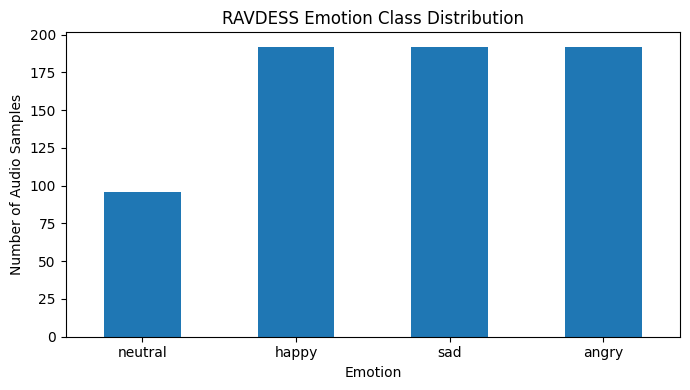

In [ ]:
plt.figure(figsize=(7, 4))

df["emotion"].value_counts().reindex(
    ["neutral", "happy", "sad", "angry"]
).plot(kind="bar")

plt.title("RAVDESS Emotion Class Distribution")
plt.xlabel("Emotion")
plt.ylabel("Number of Audio Samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Emotion: happy
Duration: 3.67 seconds


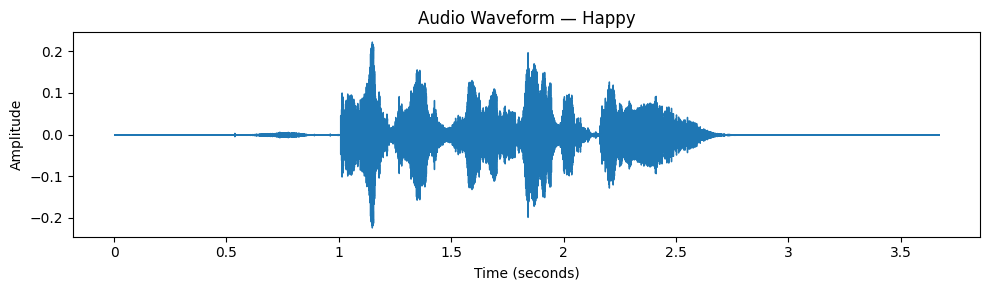

In [ ]:
from IPython.display import Audio, display

sample_path = df.iloc[0]["path"]
sample_emotion = df.iloc[0]["emotion"]

audio, sr_rate = librosa.load(sample_path, sr=22050)

print("Emotion:", sample_emotion)
print("Duration:", round(len(audio) / sr_rate, 2), "seconds")

display(Audio(audio, rate=sr_rate))

plt.figure(figsize=(10, 3))
librosa.display.waveshow(audio, sr=sr_rate)
plt.title(f"Audio Waveform — {sample_emotion.capitalize()}")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split

# Audio feature settings
SAMPLE_RATE = 22050
DURATION = 3
N_MFCC = 40
MAX_LENGTH = 130

X, y = [], []

for _, row in df.iterrows():
    try:
        audio, sr = librosa.load(
            row["path"],
            sr=SAMPLE_RATE,
            duration=DURATION
        )

        # Pad or trim audio to fixed duration
        target_length = SAMPLE_RATE * DURATION
        audio = librosa.util.fix_length(
            audio, size=target_length
        )

        # Extract MFCC features
        mfcc = librosa.feature.mfcc(
            y=audio,
            sr=SAMPLE_RATE,
            n_mfcc=N_MFCC,
            n_fft=2048,
            hop_length=512
        )

        # Ensure fixed feature length
        mfcc = librosa.util.fix_length(
            mfcc, size=MAX_LENGTH, axis=1
        )

        X.append(mfcc.T)
        y.append(row["emotion"])

    except Exception as e:
        print("Error processing:", row["path"], e)

X = np.array(X, dtype=np.float32)
y = np.array(y)

# Encode emotion labels
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)
y_categorical = to_categorical(y_encoded)

print("Feature shape:", X.shape)
print("Labels shape:", y_categorical.shape)
print("Classes:", list(encoder.classes_))

Feature shape: (672, 130, 40)
Labels shape: (672, 4)
Classes: [np.str_('angry'), np.str_('happy'), np.str_('neutral'), np.str_('sad')]


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_categorical,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 537
Testing samples: 135


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv1D, MaxPooling1D, Flatten,
    Dense, Dropout, BatchNormalization
)
from tensorflow.keras.callbacks import EarlyStopping

# Build CNN model
model = Sequential([
    Conv1D(64, kernel_size=3, activation="relu",
           input_shape=(X_train.shape[1], X_train.shape[2])),
    BatchNormalization(),
    MaxPooling1D(pool_size=2),

    Conv1D(128, kernel_size=3, activation="relu"),
    MaxPooling1D(pool_size=2),

    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.3),
    Dense(y_train.shape[1], activation="softmax")
])

# Compile model
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# Train model
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 128, 64)        │         7,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 62, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 31, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3968)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       508,032 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 541,252 (2.06 MB)

 Trainable params: 541,124 (2.06 MB)

 Non-trainable params: 128 (512.00 B)

Epoch 1/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.4452 - loss: 1.5316 - val_accuracy: 0.2685 - val_loss: 8.4396
Epoch 2/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5804 - loss: 0.8819 - val_accuracy: 0.2685 - val_loss: 6.4213
Epoch 3/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.6830 - loss: 0.7154 - val_accuracy: 0.2870 - val_loss: 6.4039
Epoch 4/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7506 - loss: 0.5950 - val_accuracy: 0.3981 - val_loss: 2.5633
Epoch 5/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7786 - loss: 0.5122 - val_accuracy: 0.4074 - val_loss: 2.8011
Epoch 6/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8415 - loss: 0.4022 - val_accuracy: 0.4074 - val_loss: 3.5283
Epoch 7/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8858 - loss: 0.3363 - val_accuracy: 0.4815 - val_loss: 2.1541
Epoch 8/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8928 - loss: 0.3122 - val_accuracy: 0.4352 - v

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, classification_report
)

# Predict test labels
y_prob = model.predict(X_test)
y_pred = np.argmax(y_prob, axis=1)
y_true = np.argmax(y_test, axis=1)

# Calculate evaluation metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(
    y_true, y_pred, average="weighted", zero_division=0
)
recall = recall_score(
    y_true, y_pred, average="weighted", zero_division=0
)
f1 = f1_score(
    y_true, y_pred, average="weighted", zero_division=0
)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
Accuracy:  0.6963
Precision: 0.7098
Recall:    0.6963
F1-score:  0.6952

Classification Report:
              precision    recall  f1-score   support

       angry       0.83      0.66      0.74        38
       happy       0.60      0.77      0.67        39
     neutral       0.64      0.47      0.55        19
         sad       0.73      0.77      0.75        39

    accuracy                           0.70       135
   macro avg       0.70      0.67      0.68       135
weighted avg       0.71      0.70      0.70       135



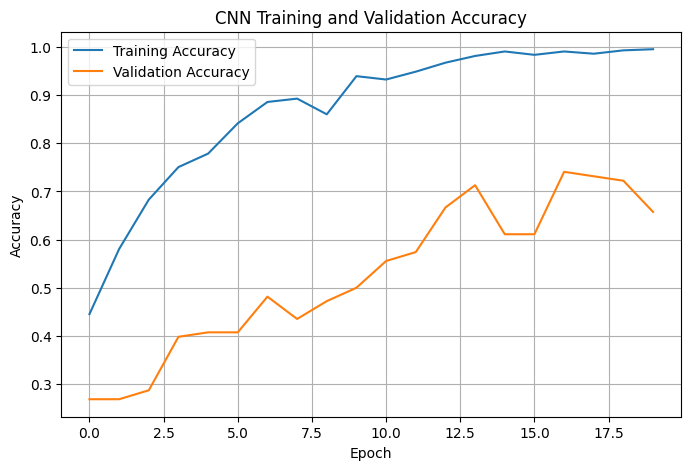

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

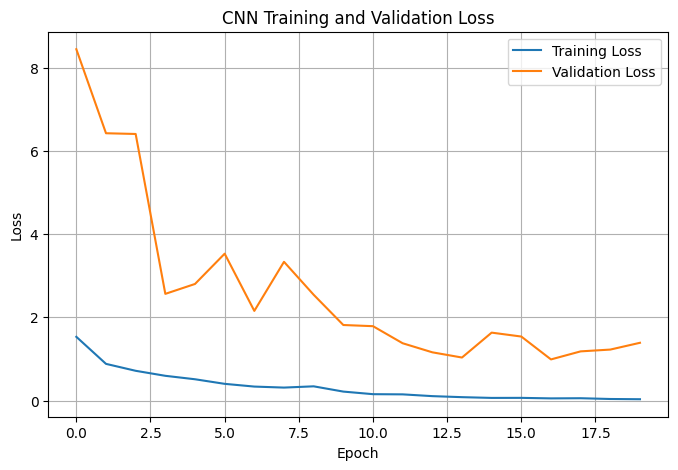

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

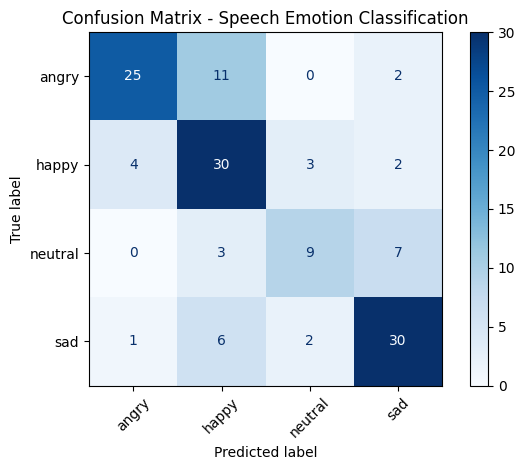

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(encoder.classes_))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=encoder.classes_
)

disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix - Speech Emotion Classification")
plt.tight_layout()
plt.show()

In [ ]:
!pip -q install SpeechRecognition

In [ ]:
import speech_recognition as sr
from google.colab import files

recognizer = sr.Recognizer()

uploaded = files.upload()
audio_path = next(iter(uploaded.keys()))

with sr.AudioFile(audio_path) as source:
    audio_data = recognizer.record(source)

try:
    transcript = recognizer.recognize_google(audio_data)
    print("Speech-to-Text Result:", transcript)

except sr.UnknownValueError:
    transcript = ""
    print("Could not understand the audio.")

except sr.RequestError as e:
    transcript = ""
    print("Recognition service error:", e)

Saving OSR_us_000_0010_8k.wav to OSR_us_000_0010_8k (1).wav
Speech-to-Text Result: the birds canoe slid on the smooth planks glue the sheet to the dark blue background it is easy to tell the depth of a well these days a chicken leg is a rare dish rice is often served in round Bowls the juice of lemons makes fine punch the box was thrown beside the park truck the Hogs are fed chopped corn and garbage 4 hours of study work face does a large size in stockings is hard to sell


In [ ]:
from gtts import gTTS
from IPython.display import Audio, display

# Use the transcript from Step 11
if transcript:
    output_text = f"The recognized speech is: {transcript}"

    # Add predicted emotion if classification was performed
    if "emotion" in globals():
        output_text += f". The predicted emotion is {emotion}"

    tts = gTTS(text=output_text, lang="en")
    tts.save("final_audio_output.mp3")

    print("Text-to-Speech Output:")
    display(Audio("final_audio_output.mp3", autoplay=False))
else:
    print("No transcript available. Complete Speech-to-Text first.")

Text-to-Speech Output:


In [ ]:
evaluation_df = pd.DataFrame([{
    "Model": "CNN (MFCC)",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1
}])

print("Speech Emotion Classification Results")
display(evaluation_df.round(4))

Speech Emotion Classification Results


,Model,Accuracy,Precision,Recall,F1-Score
0,CNN (MFCC),0.6963,0.7098,0.6963,0.6952


In [ ]:
model.save("ravdess_emotion_classifier.keras")
print("Model saved successfully.")

Model saved successfully.


In [ ]:
from google.colab import files

uploaded = files.upload()
audio_path = next(iter(uploaded.keys())) if uploaded else None

Saving Reflections-_The_Neighbourhood_Edit_Audio.wav to Reflections-_The_Neighbourhood_Edit_Audio.wav


In [ ]:
import numpy as np
import librosa

def predict_emotion(audio_path):
    audio, sr_rate = librosa.load(
        audio_path, sr=22050, duration=3
    )

    audio = librosa.util.fix_length(
        audio, size=22050 * 3
    )

    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=22050,
        n_mfcc=40,
        n_fft=2048,
        hop_length=512
    )

    mfcc = librosa.util.fix_length(
        mfcc, size=130, axis=1
    )

    features = mfcc.T[np.newaxis, ...]
    probabilities = model.predict(features, verbose=0)[0]

    predicted_index = np.argmax(probabilities)
    emotion = encoder.inverse_transform([predicted_index])[0]
    confidence = float(probabilities[predicted_index])

    return emotion, confidence

In [ ]:
if audio_path:
    emotion, confidence = predict_emotion(audio_path)

    print("Predicted Emotion:", emotion)
    print(f"Confidence: {confidence:.2%}")
else:
    print("Upload a WAV file first.")

Predicted Emotion: sad
Confidence: 99.77%
